Part 1：色散随距离累积，星座点旋转、扩散


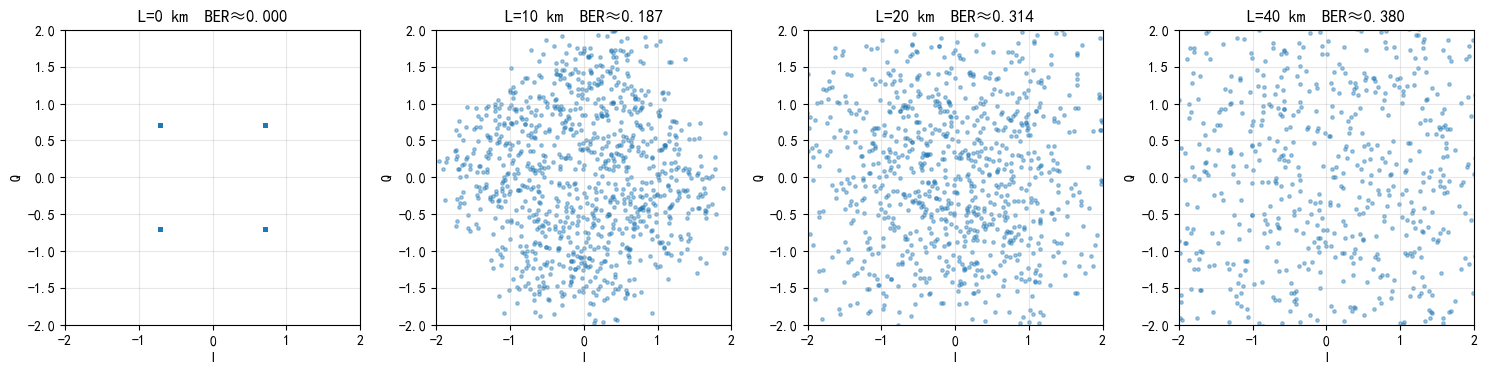

验收：距离越大，四个点越糊成一团，BER 飙升 → 这就是 DSP 要救的东西

Part 2：SSFM 传输 80 km，入纤功率 10 dBm（非线性明显区）


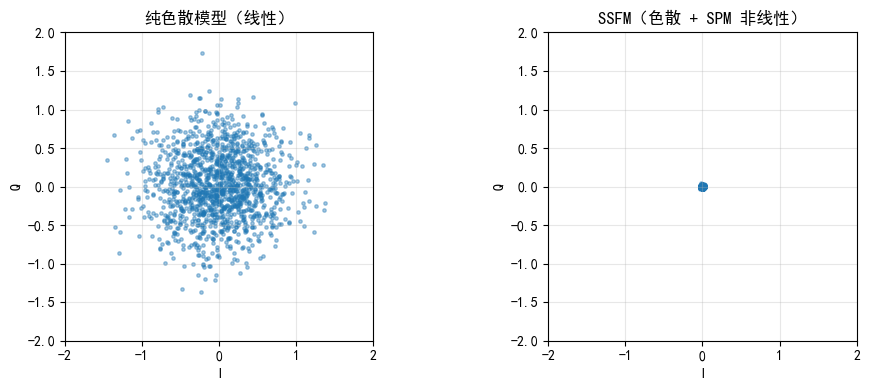

验收：SSFM 的星座比纯色散更糊、相位旋转更乱 → 非线性损伤被看到了

W3 完成。关键点：SSFM 的 batch 数据就是 W11 训练神经网络的标签来源。


In [1]:
"""
W3 · 光纤信道损伤建模（含 SSFM 分步傅里叶）
Part 1：色散传递函数 H(f)=exp(-j·β2·(2πf)^2·L/2)，扫距离看星座图劣化
Part 2：SSFM 求解 NLSE，加入非线性（SPM），与纯色散对比
运行：python w3_channel.py
产出：figures/w3_dispersion.png, figures/w3_ssfm_compare.png
"""
import os
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
os.makedirs('figures', exist_ok=True)

# ===== 全局系统参数（SI 单位）=====
Rs = 32e9                      # 符号率 32 GBaud
sps = 8                        # 每符号采样点数
Nsym = 4096                    # 符号数
N = Nsym * sps
fs = Rs * sps                  # 采样率 256 GHz
dt = 1 / fs
f = np.fft.fftfreq(N, d=dt)
omega = 2 * np.pi * f

beta2 = -21.7e-27              # GVD 系数 s^2/m（标准单模光纤 @1550nm）
alpha_db = 0.2                 # 损耗 dB/km
gamma = 1.3e-3                 # 非线性系数 1/(W·m) = 1.3 /(W·km)

# 复用 W2 的调制函数
def bits_to_qpsk(bits):
    b0, b1 = bits[0::2], bits[1::2]
    return ((1-2*b0) + 1j*(1-2*b1)) / np.sqrt(2)

def qpsk_to_bits(symbols):
    b0 = (np.real(symbols) < 0).astype(int)
    b1 = (np.imag(symbols) < 0).astype(int)
    out = np.empty(2*len(symbols), dtype=int)
    out[0::2], out[1::2] = b0, b1
    return out

np.random.seed(7)
bits = np.random.randint(0, 2, 2*Nsym)
symbols = bits_to_qpsk(bits)
# 矩形脉冲上采样（NRZ）：每个符号重复 sps 次
tx = np.repeat(symbols, sps)


def apply_dispersion(signal, L_km):
    """频域乘色散传递函数 + 损耗；末端理想放大补偿损耗（只补功率，不补色散）"""
    L = L_km * 1e3
    H = np.exp(-1j * beta2 * omega**2 * L / 2)
    y = np.fft.ifft(np.fft.fft(signal) * H)
    y *= 10**(alpha_db * L_km / 20)        # 理想 EDFA 补偿损耗
    return y


def sample_centers(signal):
    """在符号中心采样，得到均衡前的符号"""
    return signal[sps//2::sps]


# ===== Part 1：色散让星座图从清晰到糊 =====
print("Part 1：色散随距离累积，星座点旋转、扩散")
distances = [0, 10, 20, 40]    # km
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, Lkm in zip(axes, distances):
    y = apply_dispersion(tx, Lkm)
    rx_sym = sample_centers(y)
    ber = np.mean(qpsk_to_bits(rx_sym) != bits)
    ax.scatter(rx_sym[::4].real, rx_sym[::4].imag, s=6, alpha=0.4)
    ax.set_aspect('equal')
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2)
    ax.set_title(f'L={Lkm} km  BER≈{ber:.3f}')
    ax.set_xlabel('I'); ax.set_ylabel('Q'); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/w3_dispersion.png', dpi=120)
plt.show()
print("验收：距离越大，四个点越糊成一团，BER 飙升 → 这就是 DSP 要救的东西\n")


# ===== Part 2：SSFM 加入非线性（SPM）=====
def ssfm(signal, L_km, nsteps=200, P_dBm=10):
    """对称分步傅里叶：半步线性 → 非线性 → 半步线性（Strang splitting）"""
    P = 10**(P_dBm/10) * 1e-3               # dBm → W
    A = signal.copy()
    A *= np.sqrt(P / np.mean(np.abs(A)**2)) # 归一化到入纤功率
    dz = L_km * 1e3 / nsteps
    alpha = alpha_db / (4.343 * 1e3)        # dB/km → 1/m
    lin_half = np.exp(-1j * beta2 * omega**2 * dz / 4 - alpha * dz / 2)
    for _ in range(nsteps):
        A = np.fft.ifft(np.fft.fft(A) * lin_half)          # 半步线性（色散+损耗）
        A = A * np.exp(1j * gamma * np.abs(A)**2 * dz)    # 非线性相位（SPM）
        A = np.fft.ifft(np.fft.fft(A) * lin_half)          # 半步线性
    A *= 10**(alpha_db * L_km / 20)          # 末端理想放大
    return A

L_km = 80
P_dBm = 10
print(f"Part 2：SSFM 传输 {L_km} km，入纤功率 {P_dBm} dBm（非线性明显区）")
y_lin = apply_dispersion(tx * np.sqrt((10**(P_dBm/10)*1e-3)/np.mean(np.abs(tx)**2)), L_km)
y_ssfm = ssfm(tx, L_km, nsteps=200, P_dBm=P_dBm)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, y, title in [(ax[0], y_lin, '纯色散模型（线性）'),
                    (ax[1], y_ssfm, 'SSFM（色散 + SPM 非线性）')]:
    sym = sample_centers(y)
    a.scatter(sym[::3].real, sym[::3].imag, s=6, alpha=0.4)
    a.set_aspect('equal'); a.set_xlim(-2, 2); a.set_ylim(-2, 2)
    a.set_title(title); a.set_xlabel('I'); a.set_ylabel('Q'); a.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/w3_ssfm_compare.png', dpi=120)
plt.show()
print("验收：SSFM 的星座比纯色散更糊、相位旋转更乱 → 非线性损伤被看到了")
print("\nW3 完成。关键点：SSFM 的 batch 数据就是 W11 训练神经网络的标签来源。")
